In [6]:
import pandas as pd

In [7]:
df = pd.read_csv("powerplant.csv")

In [8]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [9]:
# AT - temperature
# V - Vaccum
# AP - pressure
# RH - humidity

# PE - produced energy

In [10]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [11]:
X = df.drop(columns=["PE"])
y = df["PE"]

In [12]:

X.head()
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test  = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
X_train.shape
X_test.shape

(1914, 4)

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [17]:
type(X_train_scaled)

numpy.ndarray

In [18]:
type(y_train)
y_train.shape

(7654,)

In [19]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)


In [20]:
# Define our ANN model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),

            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),

            # Output layer
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)
        

In [21]:
import torch.optim as optim

model = ANN()

# loss, optimizer

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [22]:
train_losses = []
val_losses= []
best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epoch

    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch

        optimizer.zero_grad()
        outputs = model(xb)  # forward prop....predicted outputs
        loss = criterion(outputs, yb) # compute loss
        loss.backward() # back prop.. compute gradients
        optimizer.step() # params update

        running_loss += loss.item() # Loss is a tensor => python float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)


    #Validation 
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): 
        for xb, yb in test_loader:
            outputs = model(xb) 
            loss = criterion(outputs, yb) 
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")


    

    

epoch 1/100 ==> train loss = 206595.99694010417 & val loss = 205188.5625
epoch 2/100 ==> train loss = 200877.56875 & val loss = 192955.109375
epoch 3/100 ==> train loss = 178896.5806640625 & val loss = 161633.53125
epoch 4/100 ==> train loss = 144396.88484700522 & val loss = 128751.9765625
epoch 5/100 ==> train loss = 119738.85219726563 & val loss = 112498.75
epoch 6/100 ==> train loss = 109250.16253255209 & val loss = 104112.515625
epoch 7/100 ==> train loss = 100352.69765625 & val loss = 93555.34375
epoch 8/100 ==> train loss = 86245.04488932292 & val loss = 75815.703125
epoch 9/100 ==> train loss = 63344.08779296875 & val loss = 47981.4296875
epoch 10/100 ==> train loss = 30994.627966308595 & val loss = 15564.173828125
epoch 11/100 ==> train loss = 6989.547210693359 & val loss = 2135.694580078125
epoch 12/100 ==> train loss = 980.8174996693929 & val loss = 517.8987426757812
epoch 13/100 ==> train loss = 389.53234678904215 & val loss = 336.5314025878906
epoch 14/100 ==> train loss = 

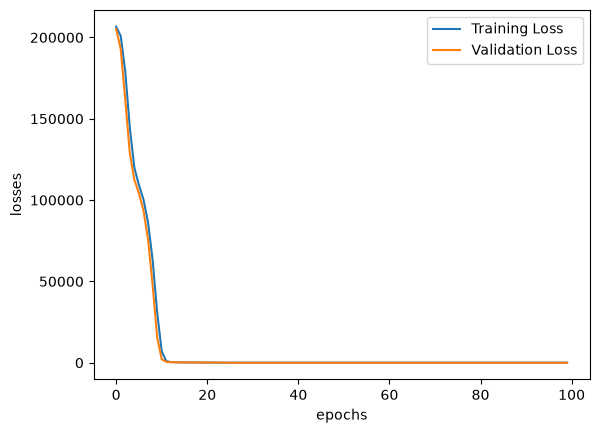

In [23]:
# visualization 

import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss")

plt.xlabel("epochs")
plt.ylabel("losses")
plt.legend()

In [24]:
#Loading the best model

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [25]:
# Evaluation 

model.eval()

with torch.no_grad():

    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds, y_train_tensor)
    test_mse_loss = criterion(test_preds, y_test_tensor)

print("Training loss:", train_mse_loss.item())
print("Testing loss:", test_mse_loss.item())

Training loss: 21.240671157836914
Testing loss: 19.532756805419922


In [26]:
from sklearn.metrics import r2_score

print("R2 score:", r2_score(y_test, test_preds))

R2 score: 0.9317380522376496


In [27]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.290131,433.27
1,436.917786,438.16
2,461.277649,458.42
3,476.209747,480.82
4,435.441772,441.41
...,...,...
1909,451.238861,456.70
1910,431.626099,438.04
1911,467.627838,467.80
1912,431.085724,437.14
